In [26]:
from pathlib import Path
from scipy import stats
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns

In [19]:
data_dir = Path("../data/raw")
columns = ["SOURCE_SUBREDDIT", "TARGET_SUBREDDIT", "POST_ID", "TIMESTAMP", "LINK_SENTIMENT","PROPERTIES"]
files = {"body": data_dir / "soc-redditHyperlinks-body.tsv",
         "title": data_dir / "soc-redditHyperlinks-title.tsv"}
for path in files.values():
    if not path.exists():
        raise FileNotFoundError(f"Missing {path}. See dataset_information.md for download instructions.")

parts = []
for location, path in files.items():
    part = pd.read_csv(path, sep="	", usecols=columns,
                       dtype={"SOURCE_SUBREDDIT": "string", "TARGET_SUBREDDIT": "string",
                              "POST_ID": "string", "TIMESTAMP": "string", "LINK_SENTIMENT": "int8"})
    part["LOCATION"] = location
    parts.append(part)
links = pd.concat(parts, ignore_index=True)
print(f"Loaded {len(links):,} links: {len(parts[0]):,} body and {len(parts[1]):,} title")

FileNotFoundError: Missing data/raw/soc-redditHyperlinks-body.tsv. See dataset_information.md for download instructions.

In [13]:
links.head()

,SOURCE_SUBREDDIT,TARGET_SUBREDDIT,POST_ID,TIMESTAMP,LINK_SENTIMENT,PROPERTIES,LOCATION
0,leagueoflegends,teamredditteams,1u4nrps,2013-12-31 16:39:58,1,"345.0,298.0,0.75652173913,0.0173913043478,0.08...",body
1,theredlion,soccer,1u4qkd,2013-12-31 18:18:37,-1,"101.0,98.0,0.742574257426,0.019801980198,0.049...",body
2,inlandempire,bikela,1u4qlzs,2014-01-01 14:54:35,1,"85.0,85.0,0.752941176471,0.0235294117647,0.082...",body
3,nfl,cfb,1u4sjvs,2013-12-31 17:37:55,1,"1124.0,949.0,0.772241992883,0.0017793594306,0....",body
4,playmygame,gamedev,1u4w5ss,2014-01-01 02:51:13,1,"715.0,622.0,0.777622377622,0.00699300699301,0....",body


## 1. Sentiment depending on location

In [20]:
stat = links.groupby("LOCATION")["LINK_SENTIMENT"].agg(
    count="count",
    positive_per=lambda s: (s == 1).mean()
)

#Compute a confidence interval
stat["se"] = np.sqrt(stat["positive_per"] * (1 - stat["positive_per"]) / stat["count"])
stat["ci_lower"] = stat["positive_per"] - 1.96 * stat["se"]
stat["ci_upper"] = stat["positive_per"] + 1.96 * stat["se"]

print(stat[["count", "positive_per", "ci_lower", "ci_upper"]])

           count  positive_per  ci_lower  ci_upper
LOCATION                                          
body      286561      0.926473  0.925517  0.927429
title     571927      0.893098  0.892297  0.893899


## 2. Time interval between first two links

In [21]:
# Parse dates before ordering links within each pair.
links["time"] = pd.to_datetime(links.pop("TIMESTAMP"), errors="coerce")
assert links["time"].notna().all()
links = links.loc[links["SOURCE_SUBREDDIT"] != links["TARGET_SUBREDDIT"]].copy()
links = links.sort_values(["time", "POST_ID", "LOCATION"]).reset_index(drop=True)

# One unordered key identifies a relationship; source and target preserve its direction.
links["pair_a"] = np.minimum(links["SOURCE_SUBREDDIT"], links["TARGET_SUBREDDIT"]).astype("string")
links["pair_b"] = np.maximum(links["SOURCE_SUBREDDIT"], links["TARGET_SUBREDDIT"]).astype("string")
links["LOCATION"] = links["LOCATION"].astype("category")

links.info()
print(f"{len(links):,} usable links in {links.groupby(['pair_a', 'pair_b']).ngroups:,} pairs")
print(f"Observed period: {links['time'].min()} to {links['time'].max()}")

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 858488 entries, 0 to 858487
Data columns (total 9 columns):
 #   Column            Non-Null Count   Dtype         
---  ------            --------------   -----         
 0   SOURCE_SUBREDDIT  858488 non-null  string        
 1   TARGET_SUBREDDIT  858488 non-null  string        
 2   POST_ID           858488 non-null  string        
 3   LINK_SENTIMENT    858488 non-null  int8          
 4   PROPERTIES        858488 non-null  object        
 5   LOCATION          858488 non-null  category      
 6   time              858488 non-null  datetime64[ns]
 7   pair_a            858488 non-null  string        
 8   pair_b            858488 non-null  string        
dtypes: category(1), datetime64[ns](1), int8(1), object(1), string(5)
memory usage: 47.5+ MB
858,488 usable links in 309,667 pairs
Observed period: 2013-12-31 16:20:20 to 2017-04-30 16:58:21


In [ ]:
# Identify the first and second recorded links of each unordered pair.
pair = links.groupby(["pair_a", "pair_b"], sort=False)
links["position_in_pair"] = pair.cumcount()
links["first_sentiment"] = pair["LINK_SENTIMENT"].transform("first")
links["first_source"] = pair["SOURCE_SUBREDDIT"].transform("first")

delta = pd.Timedelta(60, unit="D")
links["first_time"] = pair["time"].transform("first")

start_date = links["time"].min() + delta
end_date = links["time"].max() - delta

# Pairs where the first and last link happen at least 60 days 
#after the start date of the dataset and before the end date
valid_pairs = links[(links["first_time"] >= start_date) & (links["first_time"] <= end_date)]

--- Exponential Fit Results: Positive Initial Sentiment ---
Lambda rate: 0.00607 per day
Mean response time (1/lambda): 164.84 days
Estimated median time: 114.26 days
Empirical median time (from data): 81.03 days



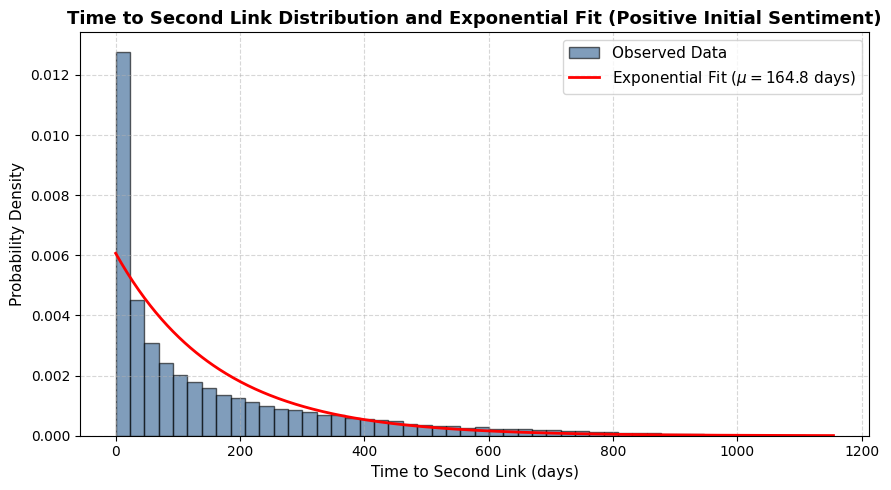

--- Exponential Fit Results: Negative Initial Sentiment ---
Lambda rate: 0.00610 per day
Mean response time (1/lambda): 163.90 days
Estimated median time: 113.61 days
Empirical median time (from data): 87.33 days



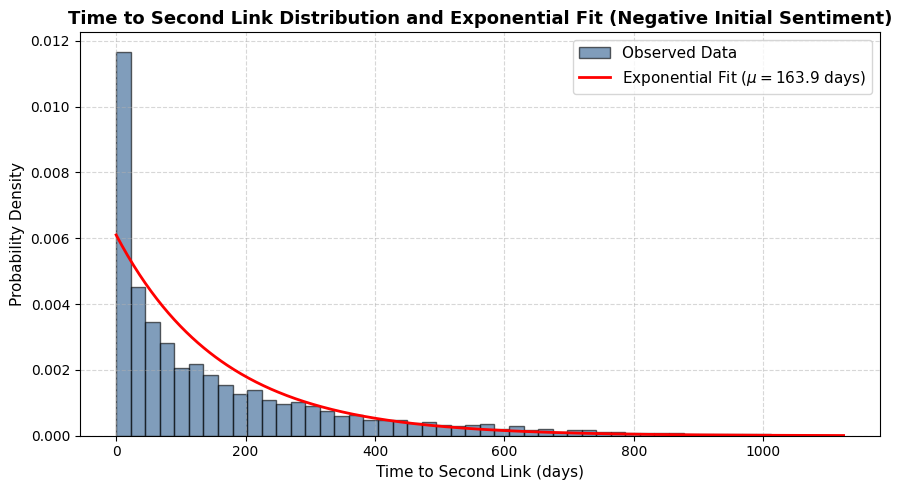

In [27]:
# 1. Keep only the first and second links
first_two = valid_pairs[valid_pairs["position_in_pair"].isin([0, 1])]

# Split into positive and negative initial sentiments
first_two_pos = first_two[first_two["first_sentiment"] == 1]
first_two_neg = first_two[first_two["first_sentiment"] == -1]

# 2. Define a reusable function for fitting and plotting
def analyze_and_plot_response_time(data_subset, title_suffix):

    # Pivot to get time of the 1st and 2nd link side by side
    pivot_times = data_subset.pivot(
        index=["pair_a", "pair_b"], columns="position_in_pair", values="time"
    )
    
    # Calculate the time difference in days
    time_diff = (pivot_times[1] - pivot_times[0])
    data = time_diff.dropna().dt.total_seconds() / 86400

    # Fit exponential with the origin to 0
    loc, scale = stats.expon.fit(data, floc=0)

    # In scipy.stats.expon: scale = 1 / lambda = Estimated mean time
    mean_response_time = scale
    lambda_param = 1.0 / scale
    median_response_time = np.log(2) / lambda_param

    # Print results
    print(f"--- Exponential Fit Results: {title_suffix} ---")
    print(f"Lambda rate: {lambda_param:.5f} per day")
    print(f"Mean response time (1/lambda): {mean_response_time:.2f} days")
    print(f"Estimated median time: {median_response_time:.2f} days")
    print(f"Empirical median time (from data): {data.median():.2f} days\n")

    # Plot visualization
    plt.figure(figsize=(9, 5))

    # density=True is used to see the probability density function
    count, bins, _ = plt.hist(
        data,
        bins=50,
        density=True,
        color="#2b5c8f",
        edgecolor="black",
        alpha=0.6,
        label="Observed Data",
    )

    # Generate points for the fitted exponential curve
    x_vals = np.linspace(0, data.max(), 500)
    pdf_fitted = stats.expon.pdf(x_vals, loc=0, scale=scale)

    plt.plot(
        x_vals,
        pdf_fitted,
        "r-",
        linewidth=2,
        label=r"Exponential Fit ($\mu={:.1f}$ days)".format(mean_response_time),
    )

    plt.title(
        f"Time to Second Link Distribution and Exponential Fit ({title_suffix})",
        fontsize=13,
        fontweight="bold",
    )
    plt.xlabel("Time to Second Link (days)", fontsize=11)
    plt.ylabel("Probability Density", fontsize=11)
    plt.legend(fontsize=11)
    plt.grid(True, linestyle="--", alpha=0.5)

    plt.tight_layout()
    plt.show()

# 3. Apply the function to both subsets
analyze_and_plot_response_time(first_two_pos, "Positive Initial Sentiment")
analyze_and_plot_response_time(first_two_neg, "Negative Initial Sentiment")

C:\Users\User\AppData\Local\Temp\ipykernel_5480\2471862815.py:2: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  first_two["first_location"] = first_two.groupby(["pair_a", "pair_b"], sort=False)["LOCATION"].transform("first")


--- Exponential Fit Results: First Link in Body ---
Lambda rate: 0.00632 per day
Mean response time (1/lambda): 158.11 days
Estimated median time: 109.59 days
Empirical median time (from data): 72.46 days



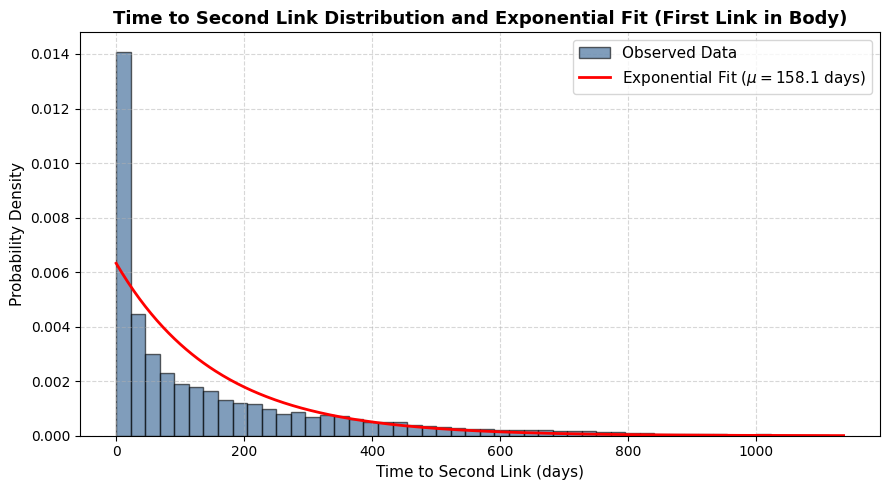

--- Exponential Fit Results: First Link in Title ---
Lambda rate: 0.00594 per day
Mean response time (1/lambda): 168.28 days
Estimated median time: 116.64 days
Empirical median time (from data): 86.19 days



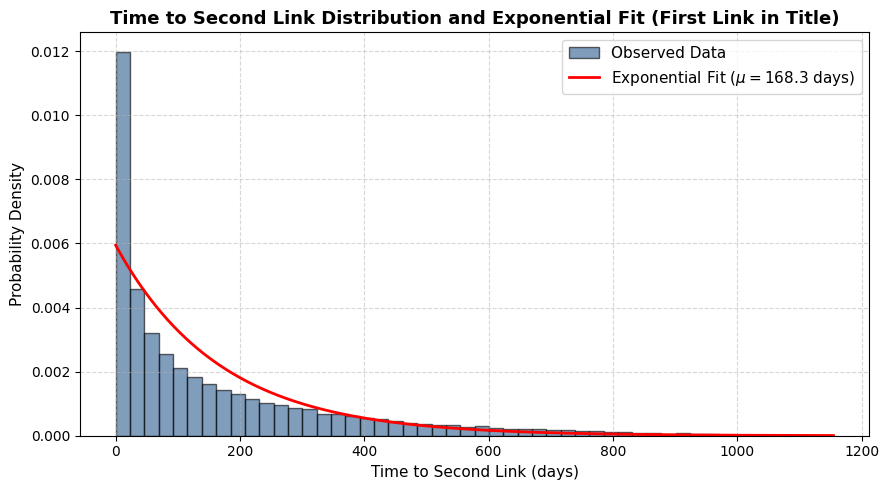

In [28]:
# 1. Keep location of first link for each pair
first_two["first_location"] = first_two.groupby(["pair_a", "pair_b"], sort=False)["LOCATION"].transform("first")

# 2. Separate data between body and title
first_two_body = first_two[first_two["first_location"] == "body"]
first_two_title = first_two[first_two["first_location"] == "title"]

# 3. Generate statistics and plots
analyze_and_plot_response_time(first_two_body, "First Link in Body")
analyze_and_plot_response_time(first_two_title, "First Link in Title")

## 3. Origin of negativity

Identify where negativity first appears in an *observed* pair history: on the first recorded link or after earlier non-negative links. For each direction, check whether its first negative link follows a negative link in the other direction.

In [29]:
# Filter only negative interactions from the valid pairs sample
neg_links = valid_pairs[valid_pairs["LINK_SENTIMENT"] == -1].copy()

# Isolate the very first negative link encountered for each unordered pair
first_neg_per_pair = neg_links.drop_duplicates(subset=["pair_a", "pair_b"], keep="first")

# Identify pairs where the first negative link appears after earlier interactions (position > 0)
late_neg_pairs = first_neg_per_pair[first_neg_per_pair["position_in_pair"] > 0]
count_late_neg = len(late_neg_pairs)

# Identify pairs where the very first interaction was already negative (position == 0)
immediate_neg_pairs = first_neg_per_pair[first_neg_per_pair["position_in_pair"] == 0]
count_immediate_neg = len(immediate_neg_pairs)


print(f"Total pairs with at least one negative link: {len(first_neg_per_pair):,}")
print(f"First negative link at position > 0 (delayed negativity): {count_late_neg:,}")
print(f"First negative link at position == 0 (hostile first contact): {count_immediate_neg:,}")

Total pairs with at least one negative link: 33,282
First negative link at position > 0 (delayed negativity): 12,477
First negative link at position == 0 (hostile first contact): 20,805


In [30]:
# 1. Filter all negative links
neg_links = valid_pairs[valid_pairs["LINK_SENTIMENT"] == -1].copy()

# 2. Identify the first negative link for each directed pair (SOURCE -> TARGET)
# Dataframe is already sorted by time, so keep="first" gets the earliest occurrence
first_directed_neg = neg_links.drop_duplicates(
    subset=["SOURCE_SUBREDDIT", "TARGET_SUBREDDIT"], 
    keep="first"
)[["SOURCE_SUBREDDIT", "TARGET_SUBREDDIT", "time"]].copy()

# Rename columns to clearly identify the direction A -> B
first_directed_neg.rename(
    columns={
        "SOURCE_SUBREDDIT": "src",
        "TARGET_SUBREDDIT": "tgt",
        "time": "time_first_neg_A_to_B"
    }, 
    inplace=True
)

# 3. Merge to find the earliest negative link in the opposite direction (B -> A)
# Match src with tgt and tgt with src
merged_directed = first_directed_neg.merge(
    first_directed_neg,
    left_on=["src", "tgt"],
    right_on=["tgt", "src"],
    how="left",
    suffixes=("", "_opp")
)

# 4. Check whether A -> B follows a prior negative link from B -> A
# Condition: opposite link exists AND happened strictly earlier
merged_directed["follows_prior_negative"] = (
    merged_directed["time_first_neg_A_to_B_opp"].notna() & 
    (merged_directed["time_first_neg_A_to_B_opp"] < merged_directed["time_first_neg_A_to_B"])
)

#Calculate the delay between B's attack and A's response
#merged_directed["retaliation_delay_days"] = (
#    (merged_directed["time_first_neg_A_to_B"] - merged_directed["time_first_neg_A_to_B_opp"])
# .dt.total_seconds() / 86400)


total_directed_neg = len(merged_directed)
follows_neg_count = merged_directed["follows_prior_negative"].sum()
first_strike_count = total_directed_neg - follows_neg_count

print(f"Total directed negative pairs (A -> B): {total_directed_neg:,}")
print(f"Follows an earlier negative link from B -> A (Retaliation): {follows_neg_count:,} ({follows_neg_count / total_directed_neg * 100:.2f}%)")
print(f"Does NOT follow an earlier negative link (First strike / Unprovoked): {first_strike_count:,} ({first_strike_count / total_directed_neg * 100:.2f}%)")

Total directed negative pairs (A -> B): 34,180
Follows an earlier negative link from B -> A (Retaliation): 898 (2.63%)
Does NOT follow an earlier negative link (First strike / Unprovoked): 33,282 (97.37%)


In [ ]:
#look at source subreddit of the second link such that we can make sure that two links are not two consecutive message from the same source
first_two["second_source"] = first_two.groupby(["pair_a", "pair_b"], sort=False)["SOURCE_SUBREDDIT"].transform("last")

#look at location of the second link
first_two["second_location"] = first_two.groupby(["pair_a", "pair_b"], sort=False)["LOCATION"].transform("last")

#keep only first link for each pair
first_two = first_two.drop_duplicates(subset=["pair_a", "pair_b"], keep="first")

#keep only links where there is a reciprocal interaction
first_two = first_two[(first_two["first_source"] != first_two["second_source"])]

#
location_transition_table = pd.crosstab(first_two["first_location"],
    first_two["second_location"], normalize="index") * 100

print(location_transition_table)


#Probablement inutile
#body_pairs = first_two[first_two["first_location"] == "body"].copy()
#title_pairs = first_two[first_two["first_location"] == "title"].copy()

#first_body_pairs = body_pairs.drop_duplicates(subset=["pair_a", "pair_b"], keep="first")
#first_title_pairs = title_pairs.drop_duplicates(subset=["pair_a", "pair_b"], keep="first")

#body_to_body = len(first_body_pairs[(first_body_pairs["first_source"] != first_body_pairs["second_source"]) & (first_body_pairs["first_location"] == first_body_pairs["second_location"])])
#first_body = len(first_body_pairs[(first_body_pairs["first_source"] != first_body_pairs["second_source"])])

#title_to_title = len(first_title_pairs[(first_title_pairs["first_source"] != first_title_pairs["second_source"]) & (first_title_pairs["first_location"] == first_title_pairs["second_location"])])
#first_title = len(first_title_pairs[(first_title_pairs["first_source"] != first_title_pairs["second_source"])])



